## EVALUATION



### 1. Thiết kế đánh giá 

Cả hai model dự đoán trên 17.686 mẫu Validation 15%.

In [1]:
from pathlib import Path
import json
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports" / "06_evaluation"
FIGURES = REPORTS / "figures"
TABLES = REPORTS / "tables"
PREPROCESSING_TABLES = ROOT / "reports" / "03_data_preprocessing" / "tables"
RESULTS = ROOT / "results"
for p in (FIGURES, TABLES, RESULTS):
    p.mkdir(parents=True, exist_ok=True)

MODEL_SOURCE = "CURRENT_SKLEARN"
MODEL_DIR = ROOT / "models"
TARGET = "Attack_type"

### 2. Nạp csv validation và ánh xạ nhãn


In [2]:
rf_val = pd.read_csv(DATA / "rf_validation.csv")
mlp_val = pd.read_csv(DATA / "mlp_validation.csv")
label_mapping = pd.read_csv(PREPROCESSING_TABLES / "05_label_mapping.csv").sort_values("class_id")
assert TARGET in rf_val.columns and TARGET in mlp_val.columns
assert rf_val.shape == mlp_val.shape == (17686, 93)
assert rf_val.columns.equals(mlp_val.columns)
assert rf_val[TARGET].equals(mlp_val[TARGET])
assert rf_val.isna().sum().sum() == 0 and mlp_val.isna().sum().sum() == 0
assert label_mapping["class_id"].tolist() == list(range(12))

feature_names = rf_val.drop(columns=TARGET).columns.tolist()
X_rf = rf_val[feature_names].to_numpy(dtype=np.float32)
X_mlp = mlp_val[feature_names].to_numpy(dtype=np.float32)
y_true = rf_val[TARGET].to_numpy(dtype=np.int64)
label_ids = label_mapping["class_id"].to_numpy(dtype=np.int64)
class_names = label_mapping[TARGET].tolist()
assert np.isfinite(X_rf).all() and np.isfinite(X_mlp).all()
assert set(np.unique(y_true)) == set(label_ids)
print("Validation:", len(y_true), "mẫu |", len(feature_names), "đặc trưng |", len(label_ids), "lớp")
display(label_mapping)

Validation: 17686 mẫu | 92 đặc trưng | 12 lớp


,class_id,Attack_type
0,0,ARP_poisioning
1,1,DDOS_Slowloris
2,2,DOS_SYN_Hping
3,3,MQTT_Publish
4,4,Metasploit_Brute_Force_SSH
5,5,NMAP_FIN_SCAN
6,6,NMAP_OS_DETECTION
7,7,NMAP_TCP_scan
8,8,NMAP_UDP_SCAN
9,9,NMAP_XMAS_TREE_SCAN


### 3. Nạp trọng số



In [3]:
rf_path = MODEL_DIR / "rf_baseline.joblib"
mlp_path = MODEL_DIR / "mlp_baseline.joblib"
missing = [str(p) for p in (rf_path, mlp_path) if not p.is_file()]
if missing:
    raise FileNotFoundError("Thiếu mô hình gốc: " + "; ".join(missing))

with warnings.catch_warnings(record=True) as captured_warnings:
    warnings.simplefilter("always", category=sklearn.exceptions.InconsistentVersionWarning)
    rf_model = joblib.load(rf_path)
    mlp_model = joblib.load(mlp_path)
orig_versions = sorted(set(str(w.message.original_sklearn_version) for w in captured_warnings
                           if isinstance(w.message, sklearn.exceptions.InconsistentVersionWarning)))

assert rf_model.n_features_in_ == mlp_model.n_features_in_ == X_rf.shape[1]
assert len(rf_model.estimators_) == 120
assert tuple(mlp_model.hidden_layer_sizes) == (64, 32)
assert len(mlp_model.loss_curve_) == 100
assert not mlp_model.early_stopping
assert set(rf_model.classes_) == set(mlp_model.classes_) == set(label_ids)
model_hashes = {"rf_baseline.joblib": hashlib.sha256(rf_path.read_bytes()).hexdigest(),
                "mlp_baseline.joblib": hashlib.sha256(mlp_path.read_bytes()).hexdigest()}
print("Đã nạp: RF", len(rf_model.estimators_), "cây; MLP", len(mlp_model.loss_curve_), "giá trị training loss")
print("scikit-learn lúc lưu mô hình:", orig_versions if orig_versions else "không xác định từ cảnh báo")
print("scikit-learn môi trường chạy:", sklearn.__version__)
if orig_versions and sklearn.__version__ not in orig_versions:
    print("LƯU Ý: khác phiên bản scikit-learn; nên chạy bằng bản gốc để tái lập nghiêm ngặt.")
for filename, sha in model_hashes.items():
    print(filename, "SHA-256:", sha)


Đã nạp: RF 120 cây; MLP 100 giá trị training loss
scikit-learn lúc lưu mô hình: không xác định từ cảnh báo
scikit-learn môi trường chạy: 1.7.2
rf_baseline.joblib SHA-256: b63e755815d15898d61d1b4f8c7fa164c3513832c3bb45f9cb55701c700347a1
mlp_baseline.joblib SHA-256: 7cb04e825d6669629b261827e750b82bba1eea0fbdb0078b6f1b0bcb4487171c


### 4. Tính các độ đo trên Validation

In [4]:
models = {"Random Forest": (rf_model, X_rf), "MLP 100 epochs": (mlp_model, X_mlp)}
preds, probabilities, rows = {}, {}, []
for model_name, (model, X) in models.items():
    y_pred = model.predict(X)
    assert len(y_pred) == len(y_true) and set(np.unique(y_pred)).issubset(set(label_ids))
    preds[model_name] = y_pred
    proba = model.predict_proba(X)
    probabilities[model_name] = proba
    rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, labels=label_ids, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, labels=label_ids, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, labels=label_ids, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=label_ids, average="weighted", zero_division=0),
        "correct_predictions": int(np.sum(y_pred == y_true)),
        "error_predictions": int(np.sum(y_pred != y_true)),
        "validation_samples": len(y_true),
    })
summary = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
summary.to_csv(TABLES / "01_overall_validation_metrics.csv", index=False, float_format="%.10f")
display(summary.style.format({c: "{:.4f}" for c in ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]}))

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,correct_predictions,error_predictions,validation_samples
0,Random Forest,0.9982,0.9698,0.9969,0.9698,0.9818,0.9982,17655,31,17686
1,MLP 100 epochs,0.9967,0.9550,0.9898,0.9550,0.9704,0.9966,17627,59,17686


### 5. Precision–Recall–F1 từng lớp và số mẫu hỗ trợ



In [5]:
per_class_list = []
for model_name, y_pred in preds.items():
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=label_ids, zero_division=0)
    per_class_list.append(pd.DataFrame({
        "model": model_name, "class_id": label_ids, "Attack_type": class_names,
        "support": s, "precision": p, "recall": r, "f1": f,
        "correct_of_class": np.diag(confusion_matrix(y_true, y_pred, labels=label_ids)),
    }))
per_class = pd.concat(per_class_list, ignore_index=True)
per_class.to_csv(TABLES / "02_per_class_validation_metrics.csv", index=False, float_format="%.10f")
display(per_class.style.format({"precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}"}))

,model,class_id,Attack_type,support,precision,recall,f1,correct_of_class
0,Random Forest,0,ARP_poisioning,1143,0.9836,0.9965,0.9900,1139
1,Random Forest,1,DDOS_Slowloris,80,1.0000,0.9500,0.9744,76
2,Random Forest,2,DOS_SYN_Hping,13513,1.0000,1.0000,1.0000,13513
3,Random Forest,3,MQTT_Publish,621,1.0000,0.9984,0.9992,620
4,Random Forest,4,Metasploit_Brute_Force_SSH,5,1.0000,1.0000,1.0000,5
5,Random Forest,5,NMAP_FIN_SCAN,4,1.0000,0.7500,0.8571,3
6,Random Forest,6,NMAP_OS_DETECTION,300,1.0000,1.0000,1.0000,300
7,Random Forest,7,NMAP_TCP_scan,151,1.0000,1.0000,1.0000,151
8,Random Forest,8,NMAP_UDP_SCAN,387,0.9846,0.9897,0.9871,383
9,Random Forest,9,NMAP_XMAS_TREE_SCAN,302,1.0000,0.9967,0.9983,301


### 6. Phân tích Recall và False Negative theo từng lớp



,Attack_type,support,TP,FN,FP,recall,f1
17,NMAP_FIN_SCAN,4,3,1,0,75.00%,0.857
13,DDOS_Slowloris,80,68,12,1,85.00%,0.913
23,Wipro_bulb,33,30,3,1,90.91%,0.938
12,ARP_poisioning,1143,1119,24,17,97.90%,0.982
20,NMAP_UDP_SCAN,387,382,5,12,98.71%,0.978
22,Thing_Speak,1147,1135,12,26,98.95%,0.984
21,NMAP_XMAS_TREE_SCAN,302,301,1,0,99.67%,0.998
15,MQTT_Publish,621,620,1,1,99.84%,0.998


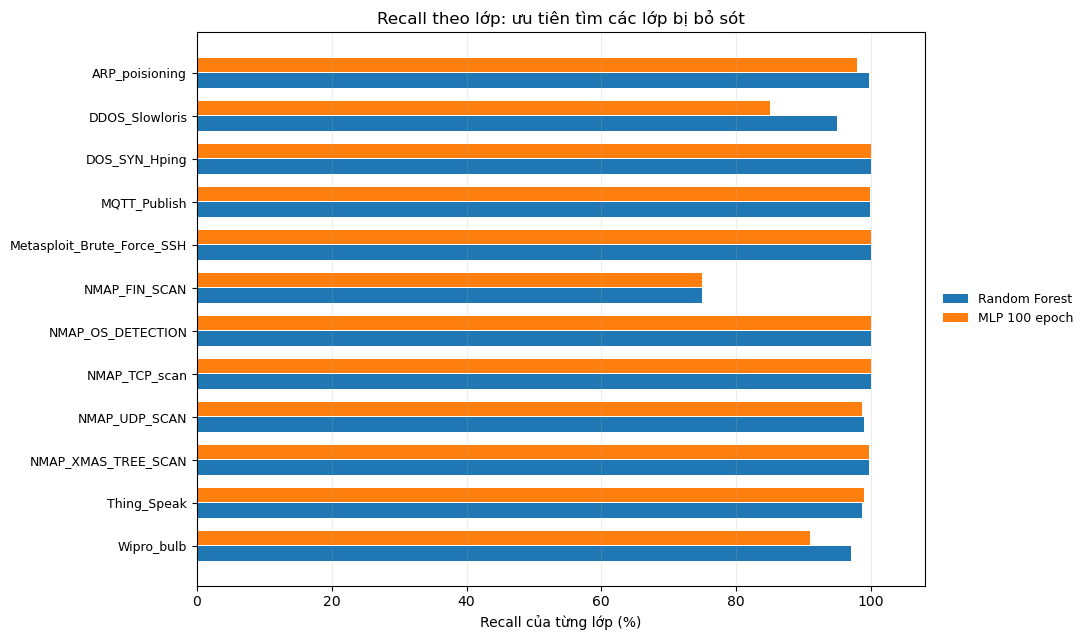

In [6]:
risk_parts = []
for model_name, y_pred in preds.items():
    cm = confusion_matrix(y_true, y_pred, labels=label_ids)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    risk_parts.append(pd.DataFrame({"model": model_name, "Attack_type": class_names,
                                    "support": cm.sum(axis=1), "TP": tp, "FN": fn, "FP": fp,
                                    "recall": tp / np.maximum(cm.sum(axis=1), 1),
                                    "f1": per_class.loc[per_class.model == model_name, "f1"].to_numpy()}))
error_by_class = pd.concat(risk_parts, ignore_index=True)
error_by_class.to_csv(TABLES / "07_recall_tp_fn_fp_by_class.csv", index=False, float_format="%.10f")
focus = error_by_class[(error_by_class["model"] == "MLP 100 epochs") & (error_by_class["FN"] > 0)].sort_values(["recall", "support"])
display(focus[["Attack_type", "support", "TP", "FN", "FP", "recall", "f1"]].style.format({"recall":"{:.2%}","f1":"{:.3f}"}))

recall_pivot = error_by_class.pivot(index="Attack_type", columns="model", values="recall").reindex(class_names)
fig, ax = plt.subplots(figsize=(11, 6.5))
positions = np.arange(len(class_names))
ax.barh(positions + 0.18, recall_pivot["Random Forest"] * 100, height=0.34, label="Random Forest")
ax.barh(positions - 0.18, recall_pivot["MLP 100 epochs"] * 100, height=0.34, label="MLP 100 epoch")
ax.set_yticks(positions, class_names, fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 108)
ax.set_xlabel("Recall của từng lớp (%)"); ax.set_title("Recall theo lớp: ưu tiên tìm các lớp bị bỏ sót")
ax.grid(axis="x", alpha=.22); ax.legend(loc="center left", bbox_to_anchor=(1.01, .50), fontsize=9, frameon=False)
fig.tight_layout(); fig.savefig(FIGURES / "04_per_class_recall_comparison.png", dpi=170)
plt.show()

### 7. Confusion Matrix – số lượng và chuẩn hóa theo lớp thực tế

Hàng là nhãn thực tế, cột là nhãn mô hình dự đoán. **Phần ngoài đường chéo** là nhầm lẫn. Ma trận số lượng cho biết số mẫu, ma trận chuẩn hóa theo hàng cho biết tỷ lệ trên từng lớp.


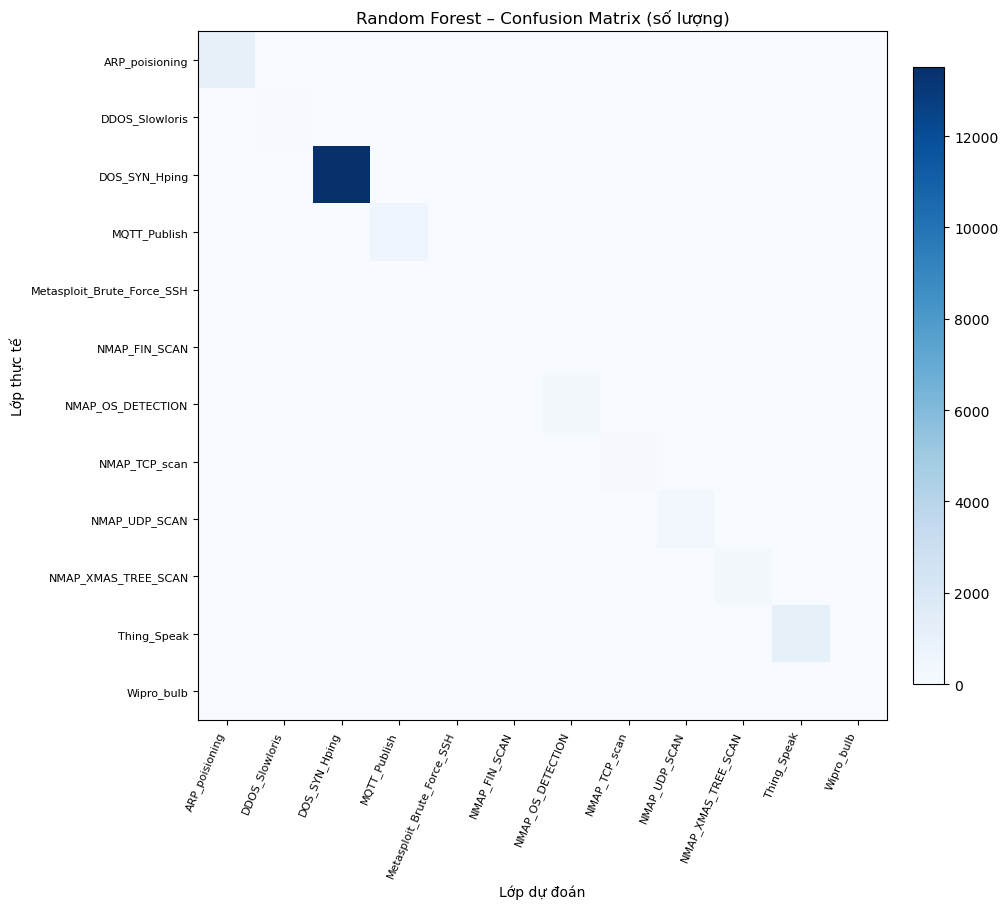

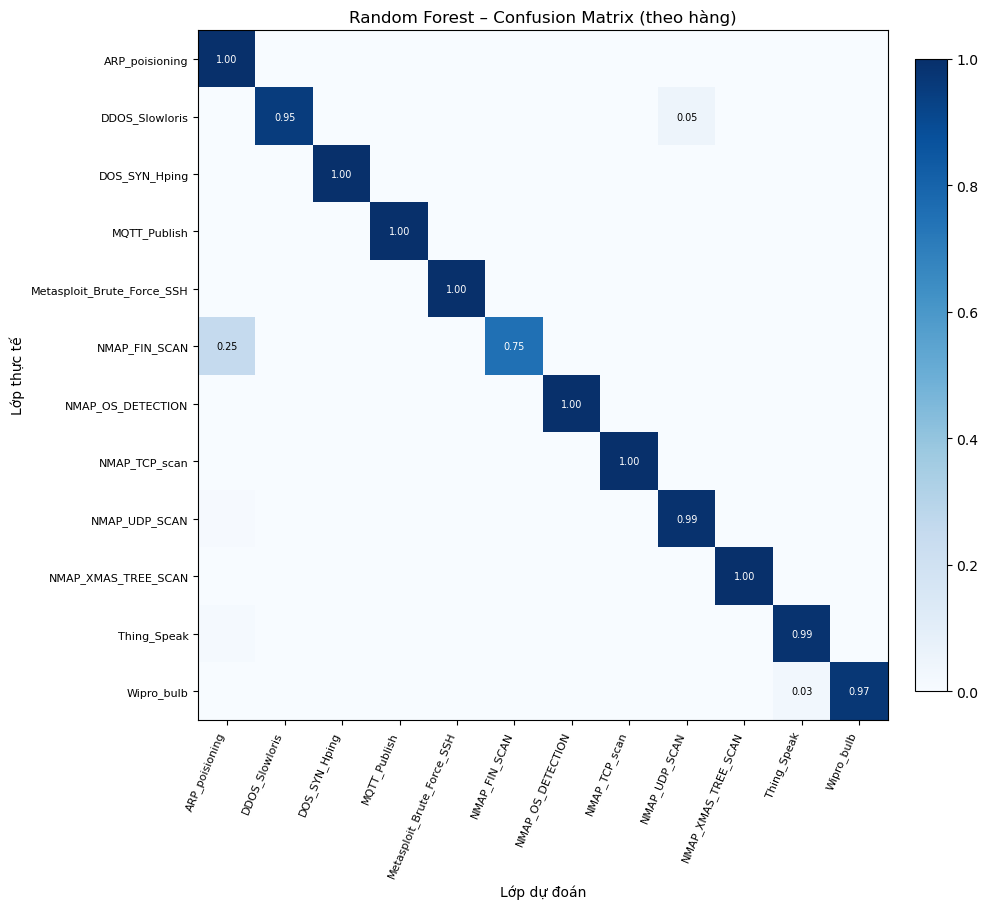

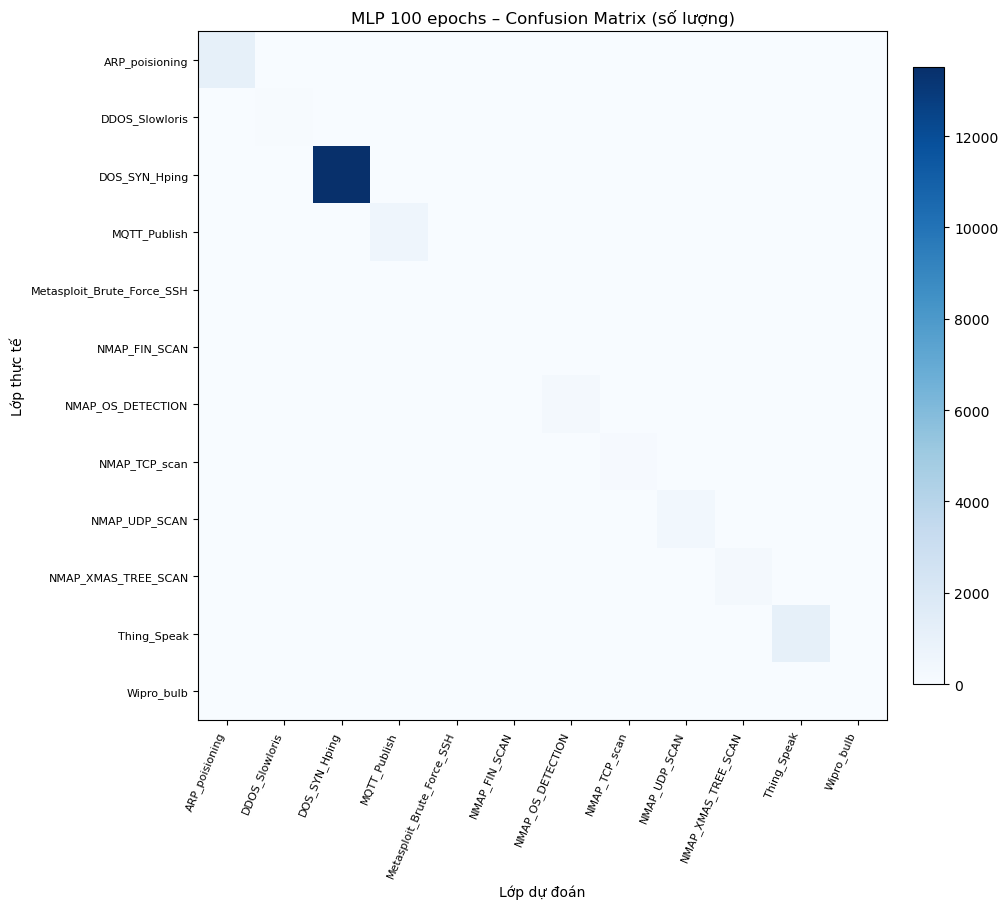

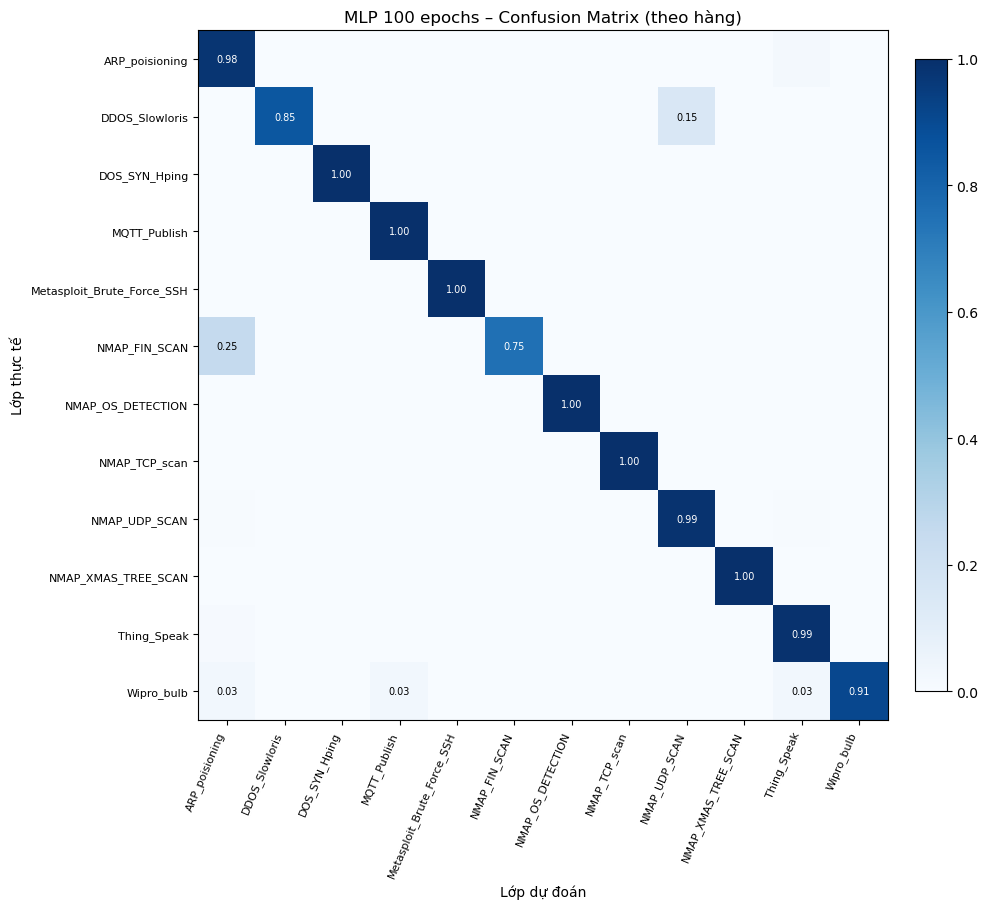

In [7]:
confusions = {}
for model_name, y_pred in preds.items():
    stem = "rf" if model_name == "Random Forest" else "mlp"
    cm = confusion_matrix(y_true, y_pred, labels=label_ids)
    confusions[model_name] = cm
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(TABLES / f"03_confusion_matrix_{stem}.csv")
    for normalized in (False, True):
        vals = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) if normalized else cm
        fig, ax = plt.subplots(figsize=(10.8, 9.2))
        im = ax.imshow(vals, cmap="Blues", vmin=0, vmax=1 if normalized else None)
        ax.set_xticks(np.arange(len(class_names)), labels=class_names, rotation=67, ha="right", fontsize=8)
        ax.set_yticks(np.arange(len(class_names)), labels=class_names, fontsize=8)
        ax.set_xlabel("Lớp dự đoán")
        ax.set_ylabel("Lớp thực tế")
        ax.set_title(f"{model_name} – Confusion Matrix ({'theo hàng' if normalized else 'số lượng'})")
        if normalized:
            for i in range(len(class_names)):
                for j in range(len(class_names)):
                    if vals[i, j] >= 0.02:
                        ax.text(j, i, f"{vals[i,j]:.2f}", ha="center", va="center", fontsize=7,
                                color="white" if vals[i, j] > 0.55 else "black")
        fig.colorbar(im, ax=ax, fraction=0.035, pad=0.03)
        fig.tight_layout()
        path = FIGURES / f"02_cm_{stem}_{'normalized' if normalized else 'counts'}.png"
        fig.savefig(path, dpi=155, bbox_inches="tight")
        plt.show()

### 8. Biểu đồ so sánh chỉ số tổng hợp và F1 từng lớp

Biểu đồ cùng thang 0–1 để không phóng đại chênh lệch nhỏ. Macro-F1 được nhấn mạnh bằng thứ tự cột trong bảng kết quả.

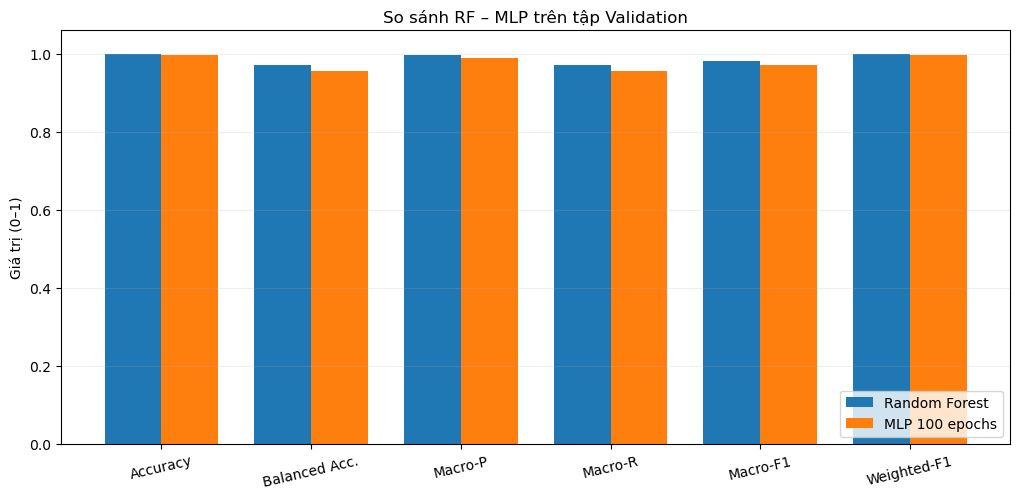

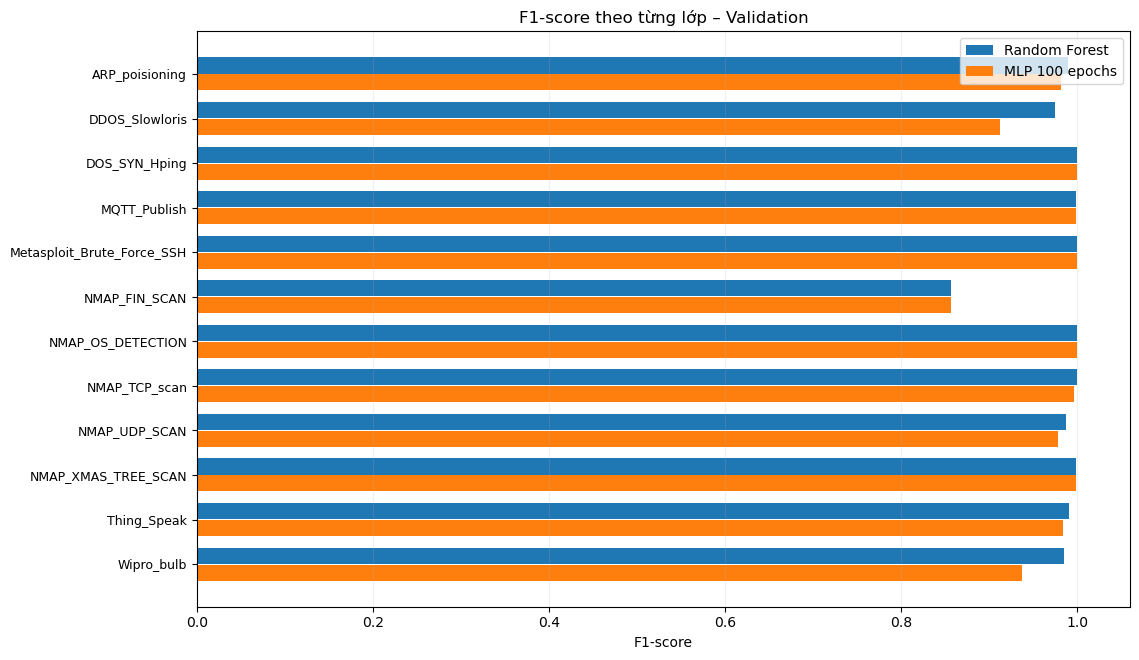

In [8]:
metric_cols = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]
metric_labels = ["Accuracy", "Balanced Acc.", "Macro-P", "Macro-R", "Macro-F1", "Weighted-F1"]
x = np.arange(len(metric_cols))
fig, ax = plt.subplots(figsize=(10.3, 5.1))
w = 0.38
for i, row in summary.iterrows():
    ax.bar(x + (i - 0.5) * w, row[metric_cols].to_numpy(dtype=float), w, label=row["model"])
ax.set_xticks(x, metric_labels, rotation=13)
ax.set_ylim(0, 1.06)
ax.set_ylabel("Giá trị (0–1)")
ax.set_title("So sánh RF – MLP trên tập Validation")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "01_overall_metrics_comparison.png", dpi=170)
plt.show()

pivot = per_class.pivot(index="Attack_type", columns="model", values="f1").reindex(class_names)
fig, ax = plt.subplots(figsize=(11.5, 6.7))
y = np.arange(len(class_names))
ax.barh(y-0.19, pivot["Random Forest"], height=0.36, label="Random Forest")
ax.barh(y+0.19, pivot["MLP 100 epochs"], height=0.36, label="MLP 100 epochs")
ax.set_yticks(y, class_names, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.06)
ax.set_xlabel("F1-score")
ax.set_title("F1-score theo từng lớp – Validation")
ax.grid(axis="x", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "03_per_class_f1_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

### 9. Lớp nào tạo ra chênh lệch Macro-F1 giữa RF và MLP?

Vì Macro-F1 là trung bình đều trên 12 lớp, đóng góp của một lớp vào chênh lệch RF−MLP bằng `(F1_RF − F1_MLP)/12`. Đây là phân rã chênh lệch quan sát được.

Macro-F1 RF cao hơn MLP 1.1415 điểm %
DDOS_Slowloris và Wipro_bulb đóng góp 0.9060/1.1415 điểm %, tức 79.37% khoảng cách.


model,Attack_type,MLP 100 epochs,Random Forest,delta_f1_rf_minus_mlp,macro_f1_gap_contribution_pp
0,DDOS_Slowloris,0.9128,0.9744,+0.0616,+0.5134
1,Wipro_bulb,0.9375,0.9846,+0.0471,+0.3926
2,NMAP_UDP_SCAN,0.9782,0.9871,+0.0089,+0.0740
3,ARP_poisioning,0.9820,0.9900,+0.0080,+0.0666
4,Thing_Speak,0.9835,0.9908,+0.0073,+0.0606
5,NMAP_TCP_scan,0.9967,1.0000,+0.0033,+0.0275
6,MQTT_Publish,0.9984,0.9992,+0.0008,+0.0067
7,DOS_SYN_Hping,1.0000,1.0000,+0.0000,+0.0000
8,Metasploit_Brute_Force_SSH,1.0000,1.0000,+0.0000,+0.0000
9,NMAP_FIN_SCAN,0.8571,0.8571,+0.0000,+0.0000


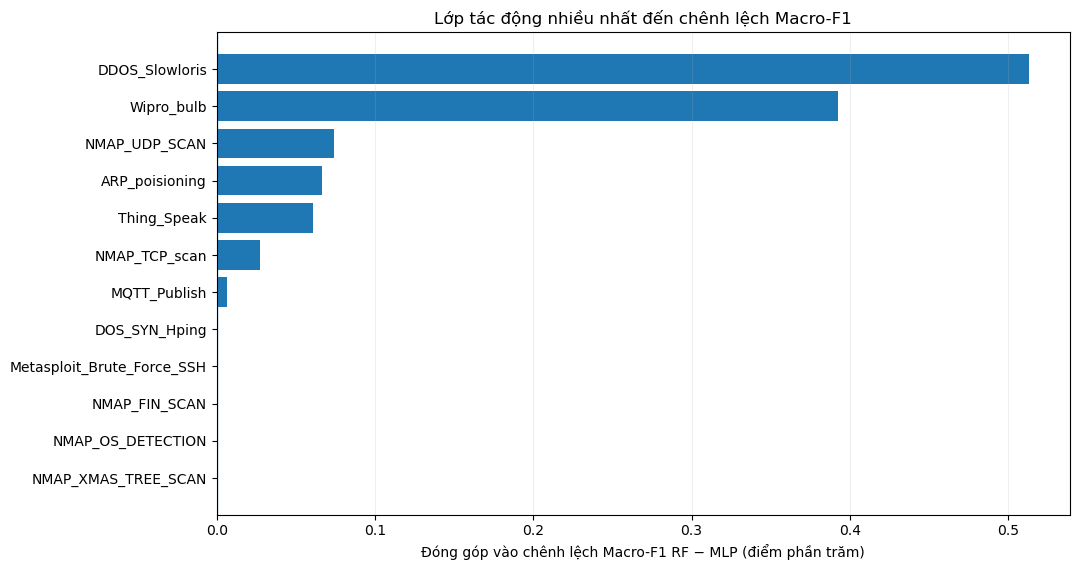

In [9]:
delta_table = (per_class.pivot(index="Attack_type", columns="model", values="f1")
               .reindex(class_names).reset_index())
delta_table["delta_f1_rf_minus_mlp"] = delta_table["Random Forest"] - delta_table["MLP 100 epochs"]
delta_table["macro_f1_gap_contribution_pp"] = delta_table["delta_f1_rf_minus_mlp"] / len(label_ids) * 100
delta_table = delta_table.sort_values("macro_f1_gap_contribution_pp", ascending=False).reset_index(drop=True)
delta_table.to_csv(TABLES / "08_macro_f1_gap_by_class.csv", index=False, float_format="%.10f")
top2_contrib = float(delta_table.head(2)["macro_f1_gap_contribution_pp"].sum())
total_gap = (summary.iloc[0]["macro_f1"] - summary.iloc[1]["macro_f1"]) * 100
print(f"Macro-F1 RF cao hơn MLP {total_gap:.4f} điểm %")
print(f"DDOS_Slowloris và Wipro_bulb đóng góp {top2_contrib:.4f}/{total_gap:.4f} điểm %, tức {top2_contrib / total_gap:.2%} khoảng cách.")
display(delta_table.style.format({"Random Forest":"{:.4f}","MLP 100 epochs":"{:.4f}","delta_f1_rf_minus_mlp":"{:+.4f}","macro_f1_gap_contribution_pp":"{:+.4f}"}))
fig, ax = plt.subplots(figsize=(10.9, 5.8))
ax.barh(delta_table["Attack_type"], delta_table["macro_f1_gap_contribution_pp"])
ax.invert_yaxis(); ax.axvline(0, linewidth=0.9)
ax.set_xlabel("Đóng góp vào chênh lệch Macro-F1 RF − MLP (điểm phần trăm)")
ax.set_title("Lớp tác động nhiều nhất đến chênh lệch Macro-F1")
ax.grid(axis="x", alpha=.2); fig.tight_layout()
fig.savefig(FIGURES / "05_macro_f1_gap_contribution.png", dpi=170);plt.show()

### 10. Phân tích lỗi và sự khác nhau giữa hai mô hình

Đếm những cặp nhầm lẫn nhiều nhất và các mẫu mà hai mô hình dự đoán khác nhau. Sử dụng số thứ tự dòng trong Validation, nhãn thực tế/dự đoán và độ tin cậy xác suất. Độ tin cậy dự đoán không đồng nghĩa với xác suất đã được hiệu chỉnh (calibrated).

In [10]:
error_cases = []
confusion_pairs = []
for model_name, y_pred in preds.items():
    proba = probabilities[model_name]
    if model_name == "Random Forest":
        stem = "rf"
        model = rf_model
    else:
        stem = "mlp"
        model = mlp_model
    pred_class_index = np.searchsorted(model.classes_, y_pred)
    max_prob = proba[np.arange(len(y_pred)), pred_class_index]
    bad = np.flatnonzero(y_pred != y_true)
    err = pd.DataFrame({
        "validation_row": bad,
        "actual_id": y_true[bad], "actual_name": [class_names[i] for i in y_true[bad]],
        "predicted_id": y_pred[bad], "predicted_name": [class_names[i] for i in y_pred[bad]],
        "predicted_class_score": max_prob[bad],
    })
    err.to_csv(TABLES / f"04_prediction_errors_{stem}.csv", index=False)
    error_cases.append((model_name, len(bad)))
    count_cm = confusions[model_name].copy()
    np.fill_diagonal(count_cm, 0)
    for i, j in zip(*np.where(count_cm > 0)):
        confusion_pairs.append({"model": model_name, "actual": class_names[i],
                                "predicted": class_names[j], "error_count": int(count_cm[i, j])})
    print(model_name, ":", len(bad), "mẫu sai; xem", f"04_prediction_errors_{stem}.csv")

pairs = pd.DataFrame(confusion_pairs).sort_values(["model", "error_count"], ascending=[True, False])
pairs.to_csv(TABLES / "05_confusion_pairs.csv", index=False)
display(pairs.groupby("model", sort=False).head(8))

rf_pred = preds["Random Forest"]
mlp_pred = preds["MLP 100 epochs"]
different = np.flatnonzero(rf_pred != mlp_pred)
disagreements = pd.DataFrame({"validation_row": different,
                              "actual": [class_names[v] for v in y_true[different]],
                              "rf_prediction": [class_names[v] for v in rf_pred[different]],
                              "mlp_prediction": [class_names[v] for v in mlp_pred[different]]})
disagreements.to_csv(TABLES / "06_model_disagreements.csv", index=False)
print("Số dòng hai mô hình dự đoán khác nhau:", len(different))

Random Forest : 31 mẫu sai; xem 04_prediction_errors_rf.csv
MLP 100 epochs : 59 mẫu sai; xem 04_prediction_errors_mlp.csv


,model,actual,predicted,error_count
11,MLP 100 epochs,ARP_poisioning,Thing_Speak,21
13,MLP 100 epochs,DDOS_Slowloris,NMAP_UDP_SCAN,12
19,MLP 100 epochs,Thing_Speak,ARP_poisioning,12
17,MLP 100 epochs,NMAP_UDP_SCAN,Thing_Speak,3
16,MLP 100 epochs,NMAP_UDP_SCAN,ARP_poisioning,2
9,MLP 100 epochs,ARP_poisioning,DDOS_Slowloris,1
10,MLP 100 epochs,ARP_poisioning,NMAP_TCP_scan,1
12,MLP 100 epochs,ARP_poisioning,Wipro_bulb,1
6,Random Forest,Thing_Speak,ARP_poisioning,14
0,Random Forest,ARP_poisioning,Thing_Speak,4


Số dòng hai mô hình dự đoán khác nhau: 51


### 11. Những cặp lớp bị nhầm


,model,actual,predicted,error_count,support,percent_of_actual_class,percent_of_model_errors
0,MLP 100 epochs,ARP_poisioning,Thing_Speak,21,1143,1.84%,35.59%
1,MLP 100 epochs,DDOS_Slowloris,NMAP_UDP_SCAN,12,80,15.00%,20.34%
2,MLP 100 epochs,Thing_Speak,ARP_poisioning,12,1147,1.05%,20.34%
3,MLP 100 epochs,NMAP_UDP_SCAN,Thing_Speak,3,387,0.78%,5.08%
4,MLP 100 epochs,NMAP_UDP_SCAN,ARP_poisioning,2,387,0.52%,3.39%
5,MLP 100 epochs,ARP_poisioning,DDOS_Slowloris,1,1143,0.09%,1.69%
14,Random Forest,Thing_Speak,ARP_poisioning,14,1147,1.22%,45.16%
15,Random Forest,ARP_poisioning,Thing_Speak,4,1143,0.35%,12.90%
16,Random Forest,DDOS_Slowloris,NMAP_UDP_SCAN,4,80,5.00%,12.90%
17,Random Forest,NMAP_UDP_SCAN,ARP_poisioning,4,387,1.03%,12.90%


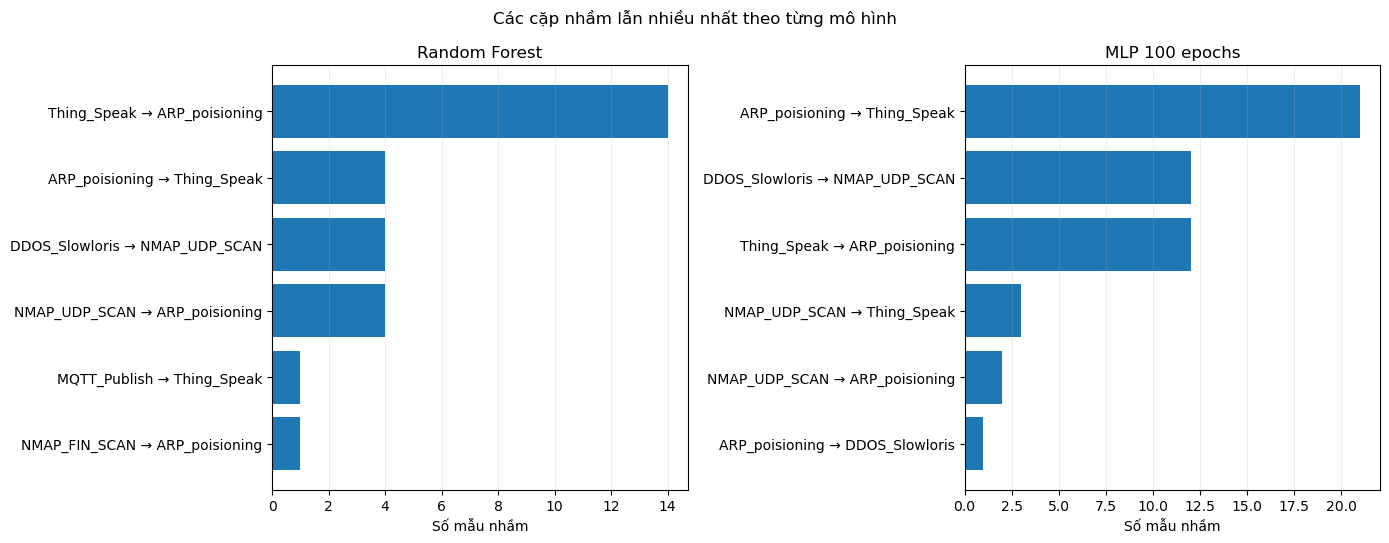

In [11]:
detail = pairs.merge(error_by_class[["model", "Attack_type", "support", "FN"]],
                     left_on=["model", "actual"], right_on=["model", "Attack_type"], how="left")
detail["percent_of_actual_class"] = detail["error_count"] / detail["support"] * 100
detail["percent_of_model_errors"] = detail["error_count"] / detail["model"].map(dict(error_cases)) * 100
detail = detail.sort_values(["model", "error_count"], ascending=[True, False])
detail.to_csv(TABLES / "09_confusion_pairs_detailed.csv", index=False, float_format="%.6f")
display(detail.groupby("model", sort=False).head(6)[["model", "actual", "predicted", "error_count", "support", "percent_of_actual_class", "percent_of_model_errors"]].style.format({"percent_of_actual_class":"{:.2f}%", "percent_of_model_errors":"{:.2f}%"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, model_name in zip(axes, ("Random Forest", "MLP 100 epochs")):
    top = detail.loc[detail.model == model_name].head(6).iloc[::-1]
    ax.barh([f"{r.actual} → {r.predicted}" for r in top.itertuples()], top["error_count"].to_numpy())
    ax.set_title(model_name);ax.set_xlabel("Số mẫu nhầm");ax.grid(axis="x", alpha=.22)
fig.suptitle("Các cặp nhầm lẫn nhiều nhất theo từng mô hình")
fig.tight_layout();fig.savefig(FIGURES / "06_top_confusion_pairs.png", dpi=170);plt.show()

### 12. Kiểm tra độ tin cậy của điểm số cao


In [12]:
rare = per_class[(per_class["model"] == "Random Forest") & (per_class["support"] <= 10)]
print("Các lớp hiếm có tối đa 10 mẫu Validation:")
display(rare[["Attack_type", "support", "correct_of_class", "recall", "f1"]])
print("Tỷ lệ lớp đông nhất trong Validation:", f"{np.max(np.bincount(y_true))/len(y_true):.2%}")

Các lớp hiếm có tối đa 10 mẫu Validation:


,Attack_type,support,correct_of_class,recall,f1
4,Metasploit_Brute_Force_SSH,5,5,1.00,1.000000
5,NMAP_FIN_SCAN,4,3,0.75,0.857143


Tỷ lệ lớp đông nhất trong Validation: 76.41%


### 13. Kết luận


In [13]:
winner = summary.iloc[0]
print("Mô hình có Macro-F1 Validation cao hơn:", winner["model"])
print("Macro-F1:", f"{winner['macro_f1']:.6f}")
metadata = {
    "model_source": MODEL_SOURCE,
    "description": "Đánh giá trực tiếp hai file joblib gốc do người dùng cung cấp; không tái huấn luyện",
    "model_sha256": model_hashes,
    "model_sklearn_original_versions": orig_versions,
    "validation_samples": int(len(y_true)),
    "n_features": int(len(feature_names)),
    "n_classes": int(len(label_ids)),
    "sklearn_version": sklearn.__version__,
    "models": {row["model"]: {key: (int(val) if isinstance(val, (np.integer,)) else float(val) if isinstance(val, (np.floating, float)) else val) for key, val in row.items() if key != "model"} for row in summary.to_dict("records")},
    "data_source": "Bước 3: rf_validation.csv, mlp_validation.csv, reports/03_data_preprocessing/tables/05_label_mapping.csv",
    "evaluation_scope": "validation only; no test access",
    "test_evaluated": False,
    "priority_metrics": ["macro_f1", "macro_recall", "per_class_recall", "confusion_matrix"],
    "macro_f1_gap_rf_minus_mlp_pp": float(total_gap),
    "top2_gap_contribution_pp": float(top2_contrib),
    "improvement_plan_status": "proposed_not_executed",
}
(RESULTS / "step6_validation_summary.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

Mô hình có Macro-F1 Validation cao hơn: Random Forest
Macro-F1: 0.981798


1758